# Part 2: Perceptron with Regularization

Training three Perceptron models on `sms_spam_perceptron.csv`:

| Model | Setting |
|---|---|
| Original | `Perceptron(penalty=None, ...)` |
| L1 | `Perceptron(penalty='l1', ...)` |
| L2 | `Perceptron(penalty='l2', ...)` |

Recall the Perceptron score: $z = \mathbf{w}^T\mathbf{x} + b$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
np.set_printoptions(precision=4, suppress=True)

## 1. Load the dataset

In [2]:
df = pd.read_csv("datasets/sms_spam_perceptron.csv")
print("Shape:", df.shape)
df.head()

Shape: (99, 3)


,type,sex,buy
0,ham,0,1
1,ham,0,1
2,ham,1,1
3,spam,1,0
4,ham,0,1


## 2. Features and labels
The `type` column is the label (spam = 1, ham = 0); all other columns (`sex`, `buy`) are the features.

In [3]:
LABEL_COL = "type"

feature_cols = [col for col in df.columns if col != LABEL_COL]
X = df[feature_cols]
y = df[LABEL_COL]

if y.dtype == object:
    y = y.str.strip().str.lower().map({"spam": 1, "ham": 0}).fillna(y)

print("Features:", feature_cols)
print("Label column:", LABEL_COL)
print(y.value_counts())

Features: ['sex', 'buy']
Label column: type
type
ham     75
spam    24
Name: count, dtype: int64


## 3. Train/test split

In [4]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (79, 2)  Test size: (20, 2)


## 4. Train the three Perceptron models
Only `penalty` changes; every other parameter is fixed.

In [5]:
COMMON_PARAMS = dict(
    max_iter=40,
    eta0=0.1,
    random_state=0,
    alpha=0.0001,
)

model_specs = {
    "Original (None)": None,
    "L1": "l1",
    "L2": "l2",
}

models, rows = {}, []
for name, penalty in model_specs.items():
    clf = Perceptron(penalty=penalty, **COMMON_PARAMS)
    clf.fit(X_train, y_train)
    models[name] = clf

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))
    w = clf.coef_.ravel()

    rows.append({
        "Model": name,
        "penalty": str(penalty),
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Bias (intercept_)": round(float(clf.intercept_[0]), 4),
        "||w||_1": round(np.abs(w).sum(), 4),
        "||w||_2": round(np.linalg.norm(w), 4),
        "max |w|": round(np.abs(w).max(), 4),
        "# zero weights": int(np.sum(np.isclose(w, 0))),
        "Epochs (n_iter_)": clf.n_iter_,
    })

results = pd.DataFrame(rows).set_index("Model")
results

,penalty,Train Accuracy,Test Accuracy,Bias (intercept_),||w||_1,||w||_2,max |w|,# zero weights,Epochs (n_iter_)
Model,,,,,,,,,
Original (None),None,0.7848,0.85,-0.5,0.4000,0.4000,0.4000,1,8
L1,l1,0.7848,0.85,-0.4,0.2937,0.2937,0.2937,1,8
L2,l2,0.7848,0.85,-0.4,0.3981,0.3979,0.3979,0,8


## 5. Learned weights (`coef_`) and bias (`intercept_`)

In [6]:
for name, clf in models.items():
    print(f"===== {name} =====")
    print("coef_ (weights):\n", clf.coef_)
    print("intercept_ (bias):", clf.intercept_)
    print()

===== Original (None) =====
coef_ (weights):
 [[0.4 0. ]]
intercept_ (bias): [-0.5]

===== L1 =====
coef_ (weights):
 [[0.2937 0.    ]]
intercept_ (bias): [-0.4]

===== L2 =====
coef_ (weights):
 [[0.3979 0.0002]]
intercept_ (bias): [-0.4]



### Weights side-by-side (one row per feature)

In [7]:
weights_table = pd.DataFrame(
    {name: clf.coef_.ravel() for name, clf in models.items()},
    index=feature_cols,
)
weights_table.loc["bias (intercept_)"] = [clf.intercept_[0] for clf in models.values()]
weights_table.round(4)

,Original (None),L1,L2
sex,0.4,0.2937,0.3979
buy,0.0,0.0000,0.0002
bias (intercept_),-0.5,-0.4000,-0.4000


## 6. Visual comparison

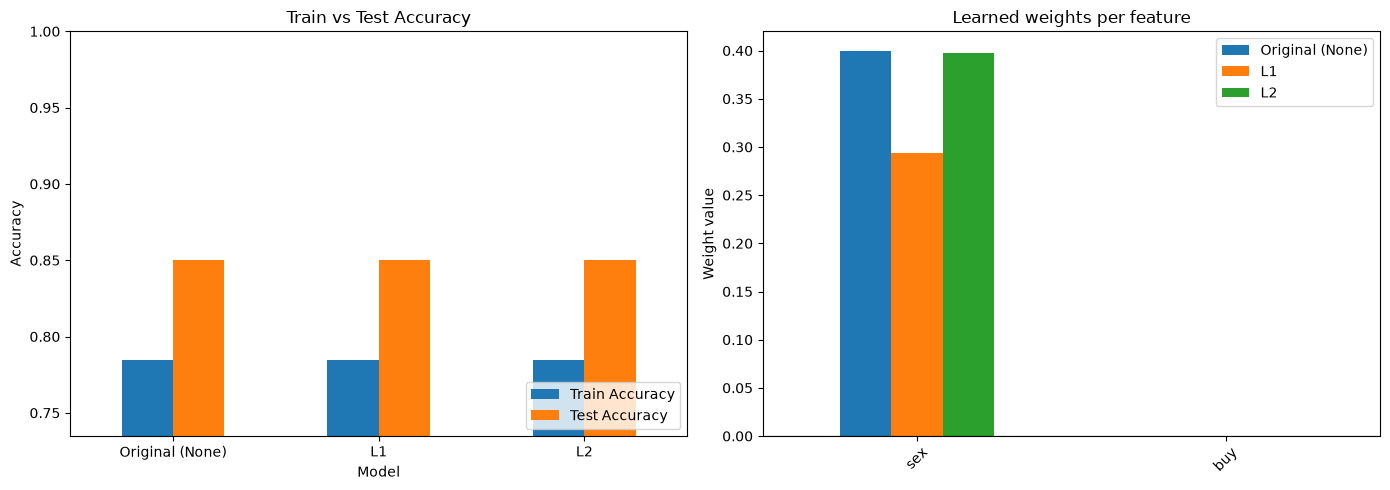

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
results[["Train Accuracy", "Test Accuracy"]].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Train vs Test Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(max(0, results[["Train Accuracy", "Test Accuracy"]].values.min() - 0.05), 1.0)
axes[0].legend(loc="lower right")

# Weight comparison
weights_table.drop(index="bias (intercept_)").plot(kind="bar", ax=axes[1])
axes[1].set_title("Learned weights per feature")
axes[1].set_ylabel("Weight value")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("part2_regularization.png", dpi=150)
plt.show()

## 7. Automatic summary of the differences

In [9]:
base = results.loc["Original (None)"]
for name in ["L1", "L2"]:
    r = results.loc[name]
    print(f"{name} vs Original:")
    print(f"  Test accuracy change : {r['Test Accuracy'] - base['Test Accuracy']:+.4f}")
    print(f"  Train accuracy change: {r['Train Accuracy'] - base['Train Accuracy']:+.4f}")
    print(f"  ||w||_2 ratio        : {r['||w||_2'] / base['||w||_2']:.3f}")
    print(f"  Zero weights         : {r['# zero weights']} (original: {base['# zero weights']})")
    print()

L1 vs Original:
  Test accuracy change : +0.0000
  Train accuracy change: +0.0000
  ||w||_2 ratio        : 0.734
  Zero weights         : 1 (original: 1)

L2 vs Original:
  Test accuracy change : +0.0000
  Train accuracy change: +0.0000
  ||w||_2 ratio        : 0.995
  Zero weights         : 0 (original: 1)



## 8. Analysis

All three models ended up with the same performance: 78.48% training accuracy and 85% testing accuracy. Adding L1 or L2 regularization did not change how well the Perceptron classified the messages. The difference between the models shows up in the learned weights.
 
| Model | Train Acc | Test Acc | $w_{sex}$ | $w_{buy}$ | Bias $b$ | $\|\mathbf{w}\|_2$ ratio |
|---|---|---|---|---|---|---|
| Original (None) | 0.7848 | 0.85 | 0.4000 | 0.0000 | -0.5 | 1.000 |
| L1 | 0.7848 | 0.85 | 0.2937 | 0.0000 | -0.4 | 0.734 |
| L2 | 0.7848 | 0.85 | 0.3979 | 0.0002 | -0.4 | 0.995 |
 
For the original Perceptron (no penalty), the weights were 0.4 for "sex" and 0.0 for "buy", with a bias of -0.5. These values are multiples of the learning rate ($\eta = 0.1$). That makes sense, because without regularization the weights only change when the model makes a mistake.
 
With L1 regularization, the "sex" weight dropped to 0.2937 and the "buy" weight stayed at exactly 0. The size of the weight vector went down to about 73% of the original ($\|\mathbf{w}\|_2$ ratio of 0.734). This matches what we expected from L1: it pushes weights toward zero by a constant amount, so weak features like "buy" get removed completely and the model becomes sparse. In a way, L1 did feature selection and decided that only "sex" matters.
 
With L2 regularization, the weights barely changed. The "sex" weight went from 0.4 to 0.3979 ($\|\mathbf{w}\|_2$ ratio of 0.995), and "buy" became a tiny nonzero value of 0.0002 instead of exactly 0. This is typical of L2: it shrinks weights in proportion to their size, so they get smaller but almost never reach zero. Because $\alpha$ was left at the default value of 0.0001, the shrinking effect was very small.
 
Accuracy didn't change because the Perceptron only looks at the sign, not its size. When we work out the decision rule for each model, they all come out the same:
 
- Original: $0.4 \cdot sex - 0.5 > 0 \Rightarrow sex \ge 2$
- L1: $0.2937 \cdot sex - 0.4 > 0 \Rightarrow sex \ge 2$
- L2: $0.3979 \cdot sex + 0.0002 \cdot buy - 0.4 > 0 \Rightarrow sex \ge 2$

All three models predict spam only when "sex" appears at least twice in a message. Regularization changed the scale of the weights but not where the decision boundary falls on this data, so every prediction was identical.
 
I also noticed that the testing accuracy (85%) was higher than the training accuracy (78.48%), which is unusual. I think this is because the test set is very small (only 20 messages, so each one is worth 5%) and happened to contain easier examples. It also shows that the model is not overfitting, which explains why regularization didn't help much. Regularization is most useful when a model has many features and starts fitting noise in the training data. This dataset has only two features and the model is already very simple, so there wasn't much overfitting to fix.
 
In conclusion, L1 made the weights smaller and sparser, and L2 shrank them only slightly. Neither one changed the training or testing accuracy on this dataset. A larger $\alpha$ or a dataset with more features would probably show a bigger difference between the three models.
